<a href="https://colab.research.google.com/github/Madihasafi/ITC-300-Data-Visualization-/blob/main/Madiha_Safi%2C_w12p2_Visualizing_Relationships_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ITC 300: Data Visualization**
## **w12p2 Visualizing Relationships**

This session groups together the source-code examples from the **w12p1 Visualizing Relationships** lecture slides.

It applies each method to the supplied Salaries dataset and explains what the code does, how to interpret the resulting visual, and what limitations must be considered.


# **Section 0: Dataset preparation**


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.patches import Rectangle
from matplotlib.ticker import StrMethodFormatter

try:
    from IPython.display import display
except ImportError:
    def display(*objects):
        for obj in objects:
            print(obj)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)

rank_order = ["AsstProf", "AssocProf", "Prof"]
rank_labels = {
    "AsstProf": "Assistant Professor",
    "AssocProf": "Associate Professor",
    "Prof": "Professor",
}
colors = {
    "AsstProf": "#79A84B",
    "AssocProf": "#EEA531",
    "Prof": "#1778B8",
}

print("Libraries and display settings are ready.")


Libraries and display settings are ready.


## 0.2 Upload and load the dataset


In [2]:
csv_candidates = [ Path("Salaries.csv")]
csv_path = next((path for path in csv_candidates if path.exists()), None)

if csv_path is None:
    from google.colab import files

    uploaded = files.upload()
    csv_path = Path(next(iter(uploaded)))

df = pd.read_csv(csv_path)
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df = df.rename(columns={
    "yrs.since.phd": "years_since_phd",
    "yrs.service": "years_service",
})

print(f"Loaded file: {csv_path.name}")
print(f"Initial shape after removing the export index: {df.shape}")
display(df.head())


Saving Salaries.csv to Salaries.csv
Loaded file: Salaries.csv
Initial shape after removing the export index: (397, 6)


,rank,discipline,years_since_phd,years_service,sex,salary
0,Prof,B,19,18,Male,139750
1,Prof,B,20,16,Male,173200
2,AsstProf,B,4,3,Male,79750
3,Prof,B,45,39,Male,115000
4,Prof,B,40,41,Male,141500


## 0.3 Validate columns and prepare data types


In [3]:
required_columns = [
    "rank", "discipline", "years_since_phd",
    "years_service", "sex", "salary",
]

missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

for column in ["years_since_phd", "years_service", "salary"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df = df.dropna(subset=required_columns).copy()

df["rank"] = pd.Categorical(
    df["rank"],
    categories=rank_order,
    ordered=True,
)

print(f"Analysis-ready shape: {df.shape}")
display(df.head())


Analysis-ready shape: (397, 6)


,rank,discipline,years_since_phd,years_service,sex,salary
0,Prof,B,19,18,Male,139750
1,Prof,B,20,16,Male,173200
2,AsstProf,B,4,3,Male,79750
3,Prof,B,45,39,Male,115000
4,Prof,B,40,41,Male,141500


## 0.4 Dataset description


In [4]:
data_audit = pd.DataFrame({
    "Measure": [
        "Complete records",
        "Missing values",
        "Academic ranks",
        "Disciplines",
        "Recorded sex categories",
        "Minimum salary",
        "Maximum salary",
    ],
    "Result": [
        len(df),
        int(df.isna().sum().sum()),
        df["rank"].nunique(),
        df["discipline"].nunique(),
        df["sex"].nunique(),
        int(df["salary"].min()),
        int(df["salary"].max()),
    ],
})

display(data_audit)
display(df[required_columns].describe(include="all"))

assert len(df) == 397
assert df.isna().sum().sum() == 0
print("Dataset validation passed.")


,Measure,Result
0,Complete records,397
1,Missing values,0
2,Academic ranks,3
3,Disciplines,2
4,Recorded sex categories,2
5,Minimum salary,57800
6,Maximum salary,231545


,rank,discipline,years_since_phd,years_service,sex,salary
count,397,397,397.000000,397.000000,397,397.000000
unique,3,2,NaN,NaN,2,NaN
top,Prof,B,NaN,NaN,Male,NaN
freq,266,216,NaN,NaN,358,NaN
mean,NaN,NaN,22.314861,17.614610,NaN,113706.458438
std,NaN,NaN,12.887003,13.006024,NaN,30289.038695
min,NaN,NaN,1.000000,0.000000,NaN,57800.000000
25%,NaN,NaN,12.000000,7.000000,NaN,91000.000000
50%,NaN,NaN,21.000000,16.000000,NaN,107300.000000
75%,NaN,NaN,32.000000,27.000000,NaN,134185.000000


Dataset validation passed.


### **Skill check 0**

1. Why should academic rank be stored as an ordered category?
2. What would `errors="coerce"` do if a salary value contained unexpected text?
3. Why is `discipline` kept as A and B instead of assigning subject names?
4. What does one row of the cleaned DataFrame represent?


In [5]:
# Write your answers as comments or insert a Markdown cell below.

# 1. Academic rank should be stored as an ordered category because
# Assistant Professor, Associate Professor, and Professor have a
# meaningful order. An ordered category preserves this order in
# tables and charts instead of treating the ranks as unrelated labels.

# 2. errors="coerce" converts values that cannot be interpreted as
# numbers into NaN. For example, unexpected text in a salary field
# becomes a missing value that can be identified and handled.

# 3. Discipline is kept as A and B because these are the categories
# recorded in the dataset. Assigning subject names without supporting
# information would introduce assumptions that the data does not justify.

# 4. One row of the cleaned DataFrame represents one faculty member's
# record, containing that person's academic rank, discipline, sex,
# years since PhD, years of service, and salary.


### **Skill check 1**

1. What does one point represent?
2. Which visual channel represents academic rank?
3. Change `alpha` to `1.0` and then `0.20`. Which version reveals overlap more clearly?
4. Does the scatterplot show that years since PhD causes salary to increase? Explain.


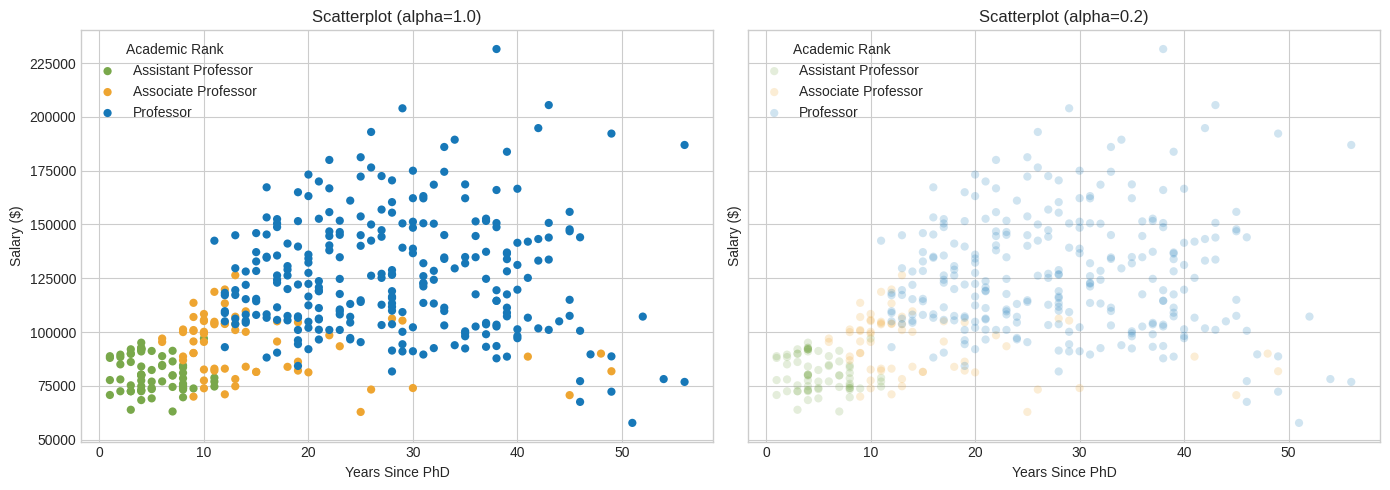

In [6]:
# Optional practice: redraw the scatterplot with a different alpha or marker size.
# Scatterplot of salary against years since PhD

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, alpha_value in zip(axes, [1.0, 0.20]):
    for rank in rank_order:
        subset = df[df["rank"] == rank]

        ax.scatter(
            subset["years_since_phd"],
            subset["salary"],
            label=rank_labels[rank],
            color=colors[rank],
            alpha=alpha_value,
            s=35,
            edgecolors="none"
        )

    ax.set_title(f"Scatterplot (alpha={alpha_value})")
    ax.set_xlabel("Years Since PhD")
    ax.set_ylabel("Salary ($)")
    ax.legend(title="Academic Rank")

plt.tight_layout()
plt.show()

Answer to the questions:
1. Each point represents one faculty member's record, showing the relationship between years since PhD and salary.

2. Color represents academic rank. The x-axis represents years since PhD, and the y-axis represents salary.

3. alpha=0.20 generally reveals overlapping observations more clearly because dense areas appear darker. alpha=1.0 makes individual points more opaque, which can hide observations behind other points.

4. No. A scatterplot can show an association between years since PhD
and salary, but it cannot establish that years since PhD causes salary to increase. Other factors, such as rank, discipline, experience, and institutional policies, may also be associated with salary.

### **Skill check 2**

1. Which rank-discipline combination contains the largest number of records?
2. Change the random seed from 12 to 30. What changes and what remains unchanged?
3. Increase the horizontal jitter range to ±0.30. Why might that become misleading?
4. Why is the contingency table necessary even when the jittered display is available?


Exact counts by academic rank and discipline:


discipline,A,B
rank,,
AsstProf,24,43
AssocProf,26,38
Prof,131,135


Largest rank-discipline combination: Prof, Discipline B (135 records)


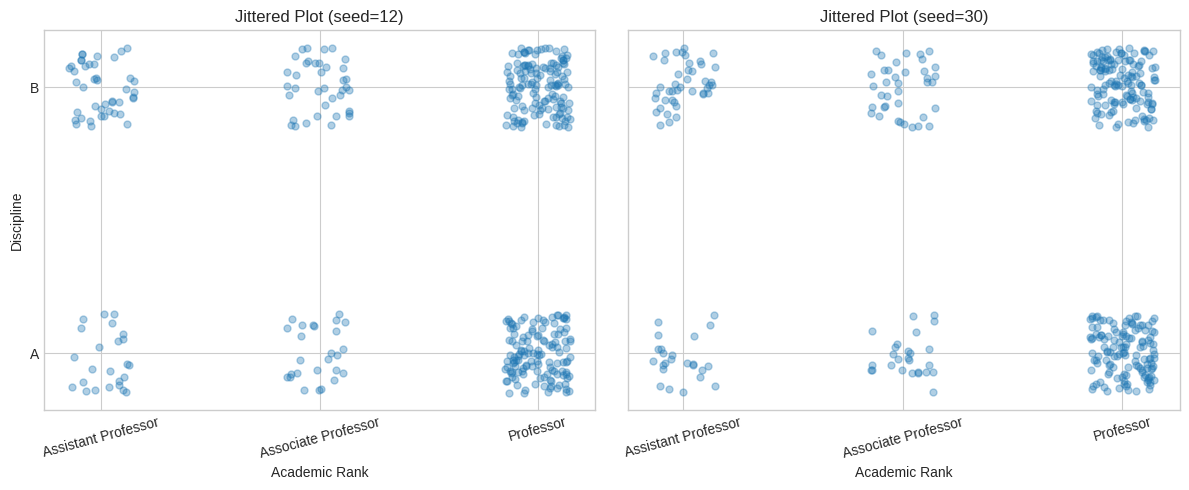

In [7]:
# Optional practice: reproduce the jitter with a new seed.
# practice_rng = np.random.default_rng(30)
# Rank and discipline

# 1. Create the exact contingency table.
rank_discipline_counts = pd.crosstab(
    df["rank"],
    df["discipline"]
).reindex(
    index=rank_order,
    columns=["A", "B"],
    fill_value=0
)

print("Exact counts by academic rank and discipline:")
display(rank_discipline_counts)

largest_cell = rank_discipline_counts.stack().idxmax()
largest_count = rank_discipline_counts.stack().max()

print(
    f"Largest rank-discipline combination: "
    f"{largest_cell[0]}, Discipline {largest_cell[1]} "
    f"({largest_count} records)"
)


# 2. Compare jittered displays using two random seeds.
# Jitter changes the positions of plotted points, not the underlying data.

rank_positions = {rank: i for i, rank in enumerate(rank_order)}
discipline_positions = {"A": 0, "B": 1}

plot_df = df.dropna(subset=["rank", "discipline"]).copy()

plot_df["rank_position"] = plot_df["rank"].astype(str).map(rank_positions)
plot_df["discipline_position"] = (
    plot_df["discipline"].astype(str).map(discipline_positions)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for ax, seed in zip(axes, [12, 30]):
    rng = np.random.default_rng(seed)

    x_jittered = (
        plot_df["rank_position"].to_numpy()
        + rng.uniform(-0.15, 0.15, len(plot_df))
    )

    y_jittered = (
        plot_df["discipline_position"].to_numpy()
        + rng.uniform(-0.15, 0.15, len(plot_df))
    )

    ax.scatter(
        x_jittered,
        y_jittered,
        alpha=0.35,
        s=25
    )

    ax.set_xticks(range(len(rank_order)))
    ax.set_xticklabels([rank_labels[r] for r in rank_order], rotation=15)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["A", "B"])
    ax.set_xlabel("Academic Rank")
    ax.set_title(f"Jittered Plot (seed={seed})")

axes[0].set_ylabel("Discipline")
plt.tight_layout()
plt.show()


Answer to the questions:
1. The code prints the rank-discipline combination with the largest exact count. Use that printed result as the answer.

2. Changing the random seed changes the random displacement of the plotted points. The exact contingency-table counts and the underlying observations remain unchanged.

3. A horizontal jitter range of ±0.30 may move points too far from their actual category positions. This can make points appear closer to neighboring categories and suggest distinctions that do not exist.

4. The contingency table provides exact counts for each combination. The jittered plot helps reveal overlapping observations, but it does not provide an equally reliable way to read exact counts.

### **Skill check 3**

1. If you replace 13 bin edges with 9 and then 17. How will the binned-median profile change?
2. If you fit a cubic polynomial with `deg=3`. Will the added flexibility clarify the data or follow noise?
3. Explain why the linear slope should not be interpreted causally.
4. Identify the binned interval with the smallest sample size.


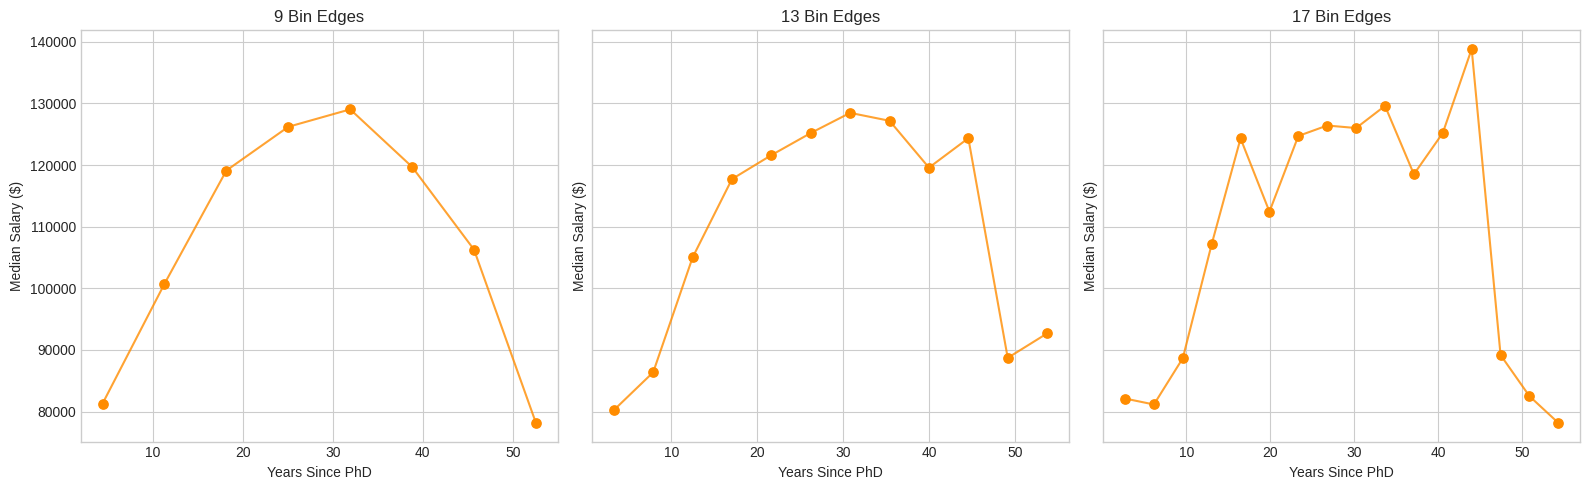

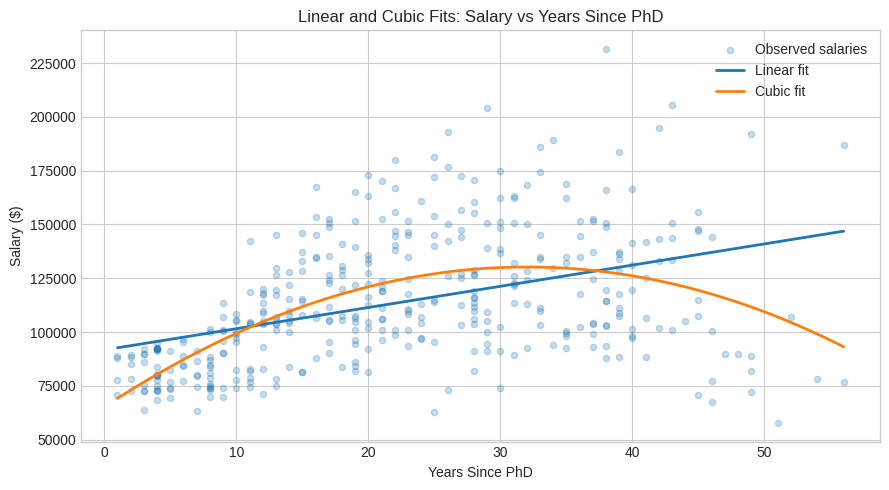

Binned summary using 13 edges:


,count,median
bin,,
"(0.999, 5.583]",42,80225.0
"(5.583, 10.167]",45,86373.0
"(10.167, 14.75]",43,105000.0
"(14.75, 19.333]",50,117717.5
"(19.333, 23.917]",44,121603.0
"(23.917, 28.5]",45,125192.0
"(28.5, 33.083]",41,128464.0
"(33.083, 37.667]",24,127175.0
"(37.667, 42.25]",36,119575.0


Interval with the smallest nonempty sample: (51.417, 56.0] (4 records)


In [8]:
# Optional practice: test another polynomial degree or bin count.
# cubic = np.poly1d(np.polyfit(x, y, deg=3))

# Binned medians and polynomial fits

x = df["years_since_phd"].to_numpy(dtype=float)
y = df["salary"].to_numpy(dtype=float)

# Sort observations by x for plotting fitted curves.
sort_idx = np.argsort(x)
x_sorted = x[sort_idx]
y_sorted = y[sort_idx]


# Helper function: calculate median salary within equal-width bins.
def calculate_binned_medians(data, number_of_edges):
    bin_edges = np.linspace(
        data["years_since_phd"].min(),
        data["years_since_phd"].max(),
        number_of_edges
    )

    binned = data.copy()
    binned["bin"] = pd.cut(
        binned["years_since_phd"],
        bins=bin_edges,
        include_lowest=True
    )

    summary = (
        binned.groupby("bin", observed=False)["salary"]
        .agg(["count", "median"])
        .dropna(subset=["median"])
    )

    summary["midpoint"] = [
        interval.mid for interval in summary.index
    ]

    return summary


fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, number_of_edges in zip(axes, [9, 13, 17]):
    summary = calculate_binned_medians(df, number_of_edges)

    ax.scatter(
        summary["midpoint"],
        summary["median"],
        color="darkorange",
        s=45
    )

    ax.plot(
        summary["midpoint"],
        summary["median"],
        color="darkorange",
        alpha=0.8
    )

    ax.set_title(f"{number_of_edges} Bin Edges")
    ax.set_xlabel("Years Since PhD")
    ax.set_ylabel("Median Salary ($)")

plt.tight_layout()
plt.show()


# Fit linear and cubic polynomial models.
linear_fit = np.poly1d(np.polyfit(x, y, deg=1))
cubic_fit = np.poly1d(np.polyfit(x, y, deg=3))

x_grid = np.linspace(x.min(), x.max(), 300)

plt.figure(figsize=(9, 5))
plt.scatter(x, y, alpha=0.25, s=20, label="Observed salaries")
plt.plot(
    x_grid,
    linear_fit(x_grid),
    label="Linear fit",
    linewidth=2
)
plt.plot(
    x_grid,
    cubic_fit(x_grid),
    label="Cubic fit",
    linewidth=2
)

plt.title("Linear and Cubic Fits: Salary vs Years Since PhD")
plt.xlabel("Years Since PhD")
plt.ylabel("Salary ($)")
plt.legend()
plt.tight_layout()
plt.show()


# Identify the interval with the smallest sample size using 13 edges.
bin_summary = calculate_binned_medians(df, 13)

print("Binned summary using 13 edges:")
display(bin_summary[["count", "median"]])

smallest_bin = bin_summary["count"].idxmin()
smallest_bin_count = bin_summary["count"].min()

print(
    f"Interval with the smallest nonempty sample: {smallest_bin} "
    f"({smallest_bin_count} records)"
)


Answer to the questions:
1. With 9 bin edges, there are fewer and wider bins, so the median profile is generally smoother but contains less detail. With 17 edges, there are more and narrower bins, so local variation becomes more visible, but the profile may be less stable. The exact pattern depends on the distribution of observations.

2. A cubic polynomial is more flexible than a straight line and can capture curvature. However, that flexibility may also follow noise. The cubic fit should not automatically be considered better; it should be evaluated against the data and the purpose of the analysis.

3. The linear slope describes an association in the observed data. It does not establish causation because other variables may influence salary, and the scatterplot is observational rather than experimental.

4. The code prints the nonempty binned interval with the smallest sample size. Use that interval and its count as the answer.

### **Skill check 4**

1. At which rank is the absolute difference between the two means largest?
2. Why should the unequal group counts be considered?
3. Why should the connected profiles not be described as salary growth through time?
4. Remove the markers. Does the chart become easier or harder to read with only three rank positions?


Mean salary by rank and sex:


sex,Female,Male
rank,,
AsstProf,78049.91,81311.46
AssocProf,88512.80,94869.70
Prof,121967.61,127120.82


Number of observations by rank and sex:


sex,Female,Male
rank,,
AsstProf,11,56
AssocProf,10,54
Prof,18,248


Salary profile comparison:


,Male mean,Female mean,Male count,Female count,Male minus Female,Absolute difference
AsstProf,81311.46,78049.91,56,11,3261.56,3261.56
AssocProf,94869.70,88512.80,54,10,6356.90,6356.90
Prof,127120.82,121967.61,248,18,5153.21,5153.21


Largest absolute difference: AssocProf (6356.90)


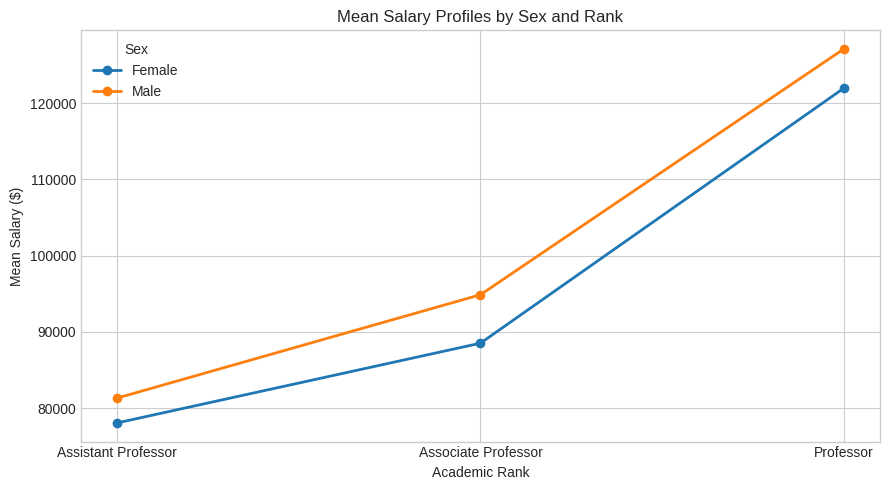

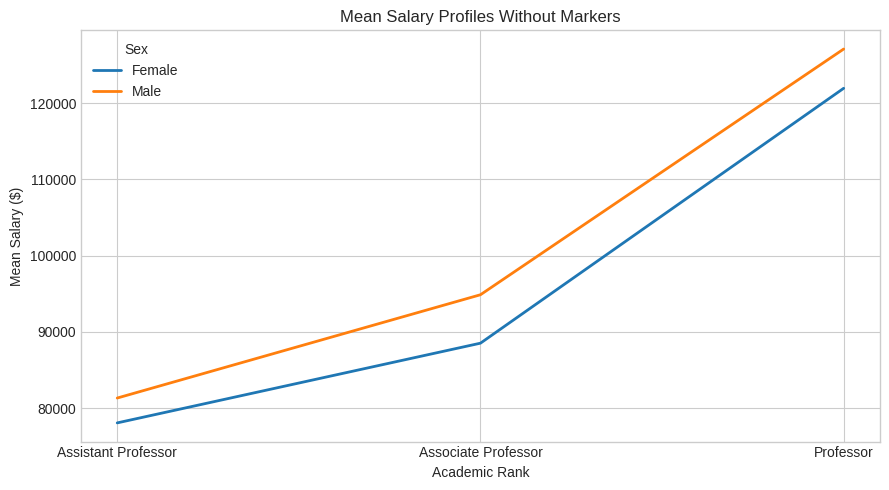

In [9]:
# Optional practice: identify the largest absolute difference.
# profile_check["Absolute difference"] = profile_check["Male minus Female"].abs()
# Mean salary profiles by sex and academic rank

profile_check = (
    df.groupby(["rank", "sex"], observed=True)["salary"]
    .agg(["mean", "count"])
    .reset_index()
)

mean_profiles = profile_check.pivot(
    index="rank",
    columns="sex",
    values="mean"
).reindex(rank_order)

count_profiles = profile_check.pivot(
    index="rank",
    columns="sex",
    values="count"
).reindex(rank_order)

print("Mean salary by rank and sex:")
display(mean_profiles.round(2))

print("Number of observations by rank and sex:")
display(count_profiles)

# Identify male and female columns robustly.
sex_lookup = {
    str(value).strip().lower(): value
    for value in mean_profiles.columns
}

male_column = next(
    (value for key, value in sex_lookup.items()
     if key in ["male", "m"]),
    None
)

female_column = next(
    (value for key, value in sex_lookup.items()
     if key in ["female", "f"]),
    None
)

if male_column is None or female_column is None:
    print(
        "Check the sex category labels above. "
        "The code could not identify both Male and Female automatically."
    )
else:
    profile_check_table = pd.DataFrame(index=rank_order)

    profile_check_table["Male mean"] = mean_profiles[male_column]
    profile_check_table["Female mean"] = mean_profiles[female_column]
    profile_check_table["Male count"] = count_profiles[male_column]
    profile_check_table["Female count"] = count_profiles[female_column]

    profile_check_table["Male minus Female"] = (
        profile_check_table["Male mean"]
        - profile_check_table["Female mean"]
    )

    profile_check_table["Absolute difference"] = (
        profile_check_table["Male minus Female"].abs()
    )

    print("Salary profile comparison:")
    display(profile_check_table.round(2))

    largest_difference_rank = (
        profile_check_table["Absolute difference"].idxmax()
    )

    print(
        f"Largest absolute difference: {largest_difference_rank} "
        f"({profile_check_table.loc[largest_difference_rank, 'Absolute difference']:.2f})"
    )


# Plot profiles with markers.
fig, ax = plt.subplots(figsize=(9, 5))

for sex_value in mean_profiles.columns:
    ax.plot(
        range(len(rank_order)),
        mean_profiles[sex_value],
        marker="o",
        linewidth=2,
        label=str(sex_value)
    )

ax.set_xticks(range(len(rank_order)))
ax.set_xticklabels([rank_labels[r] for r in rank_order])
ax.set_xlabel("Academic Rank")
ax.set_ylabel("Mean Salary ($)")
ax.set_title("Mean Salary Profiles by Sex and Rank")
ax.legend(title="Sex")
plt.tight_layout()
plt.show()


# Plot the same profiles without markers for comparison.
fig, ax = plt.subplots(figsize=(9, 5))

for sex_value in mean_profiles.columns:
    ax.plot(
        range(len(rank_order)),
        mean_profiles[sex_value],
        linewidth=2,
        label=str(sex_value)
    )

ax.set_xticks(range(len(rank_order)))
ax.set_xticklabels([rank_labels[r] for r in rank_order])
ax.set_xlabel("Academic Rank")
ax.set_ylabel("Mean Salary ($)")
ax.set_title("Mean Salary Profiles Without Markers")
ax.legend(title="Sex")
plt.tight_layout()
plt.show()

Answer to the questions:
1. The code calculates the absolute difference between male and female mean salaries for each rank and prints the rank with the largest difference. Report the rank and value printed.

2. The number of observations may differ substantially between the groups. A mean calculated from a small group can be less stable than one calculated from a larger group. The group counts provide necessary context for interpreting the means, although sample size alone does not determine whether a difference is meaningful.

3. The horizontal axis represents academic ranks, not time. Connecting the mean values is a visual aid for comparing ordered categories; it does not represent salary growth experienced by individual faculty members over time.

4. Removing markers may make the overall direction of the profiles easier to see, but it makes the three rank positions less explicit. With only three categories, markers generally help readers identify the values used to draw the lines.

### **Skill check 5**

1. Which rank-discipline cell has the largest exact count?
2. Which rank has the largest share of the full sample?
3. Within which rank are disciplines A and B most evenly represented?
4. Explain the difference between mosaic width, height, and area.
5. Why would scaling each table-plot row independently change the question?


Exact counts:


discipline,A,B
rank,,
AsstProf,24,43
AssocProf,26,38
Prof,131,135


Largest exact cell: Prof, Discipline B (135 records)
Rank counts and sample shares:


,Count,Share (%)
rank,,
AsstProf,67,16.88
AssocProf,64,16.12
Prof,266,67.00


Rank with the largest sample share: Prof (67.00%)
Discipline percentages within each rank:


discipline,A,B
rank,,
AsstProf,35.82,64.18
AssocProf,40.62,59.38
Prof,49.25,50.75


Absolute percentage-point gaps between A and B:


,Absolute Gap (percentage points)
rank,
AsstProf,28.36
AssocProf,18.75
Prof,1.50


Most evenly represented disciplines: Prof (absolute percentage-point gap = 1.50)


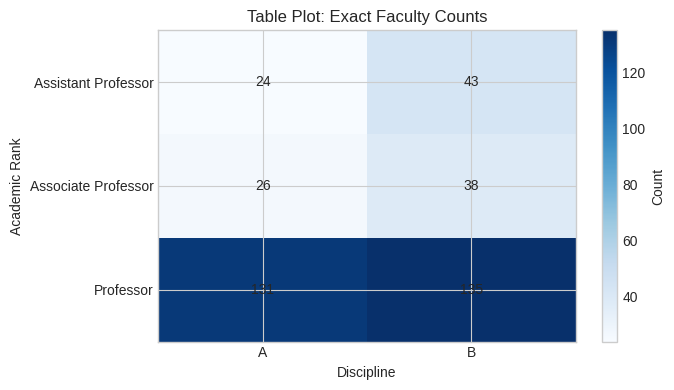

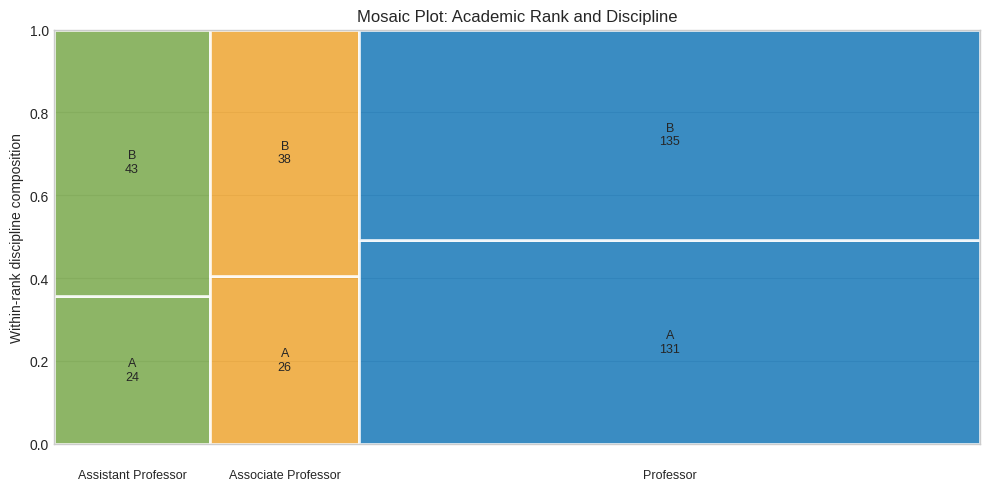

In [10]:
# Optional practice: calculate the absolute difference between A and B percentages per rank.
# composition_gap = (shares["A"] - shares["B"]).abs()
# display(composition_gap.sort_values())
# Rank and discipline composition

# Exact contingency table.
counts = pd.crosstab(
    df["rank"],
    df["discipline"]
).reindex(
    index=rank_order,
    columns=["A", "B"],
    fill_value=0
)

print("Exact counts:")
display(counts)

# 1. Largest exact rank-discipline cell.
largest_cell = counts.stack().idxmax()
largest_cell_count = counts.stack().max()

print(
    f"Largest exact cell: {largest_cell[0]}, "
    f"Discipline {largest_cell[1]} ({largest_cell_count} records)"
)


# 2. Share of the complete sample in each rank.
rank_counts = counts.sum(axis=1)
rank_shares = rank_counts / rank_counts.sum() * 100

print("Rank counts and sample shares:")
display(pd.DataFrame({
    "Count": rank_counts,
    "Share (%)": rank_shares
}).round(2))

largest_rank_share = rank_shares.idxmax()

print(
    f"Rank with the largest sample share: {largest_rank_share} "
    f"({rank_shares.loc[largest_rank_share]:.2f}%)"
)


# 3. Find the rank where A and B are most evenly represented.
shares = counts.div(counts.sum(axis=1), axis=0) * 100

composition_gap = (shares["A"] - shares["B"]).abs()

print("Discipline percentages within each rank:")
display(shares.round(2))

print("Absolute percentage-point gaps between A and B:")
display(composition_gap.to_frame("Absolute Gap (percentage points)").round(2))

most_even_rank = composition_gap.idxmin()

print(
    f"Most evenly represented disciplines: {most_even_rank} "
    f"(absolute percentage-point gap = {composition_gap.loc[most_even_rank]:.2f})"
)


# 4. Table plot: exact counts represented by a colored grid.
fig, ax = plt.subplots(figsize=(7, 4))

matrix = counts.to_numpy()

im = ax.imshow(matrix, aspect="auto", cmap="Blues")

ax.set_xticks(range(len(counts.columns)))
ax.set_xticklabels(counts.columns)
ax.set_yticks(range(len(counts.index)))
ax.set_yticklabels([rank_labels[str(r)] for r in counts.index])

ax.set_xlabel("Discipline")
ax.set_ylabel("Academic Rank")
ax.set_title("Table Plot: Exact Faculty Counts")

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(
            j, i, str(matrix[i, j]),
            ha="center", va="center"
        )

fig.colorbar(im, ax=ax, label="Count")
plt.tight_layout()
plt.show()


# 5. Mosaic plot: widths reflect rank counts; heights reflect the
# discipline shares within each rank; tile areas reflect joint shares.
fig, ax = plt.subplots(figsize=(10, 5))

total_count = counts.to_numpy().sum()
x_start = 0.0

for rank in rank_order:
    rank_total = counts.loc[rank].sum()

    if rank_total == 0:
        continue

    width = rank_total / total_count
    y_start = 0.0

    for discipline in ["A", "B"]:
        cell_count = counts.loc[rank, discipline]
        height = cell_count / rank_total

        rect = Rectangle(
            (x_start, y_start),
            width,
            height,
            facecolor=colors[rank],
            edgecolor="white",
            linewidth=2,
            alpha=0.85
        )
        ax.add_patch(rect)

        if cell_count > 0:
            ax.text(
                x_start + width / 2,
                y_start + height / 2,
                f"{discipline}\n{cell_count}",
                ha="center",
                va="center",
                fontsize=9
            )

        y_start += height

    ax.text(
        x_start + width / 2,
        -0.06,
        rank_labels[rank],
        ha="center",
        va="top",
        rotation=0,
        fontsize=9
    )

    x_start += width

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_ylabel("Within-rank discipline composition")
ax.set_title("Mosaic Plot: Academic Rank and Discipline")
ax.set_xticks([])
plt.tight_layout()
plt.show()

Answer to the questions:

1. The code prints the rank-discipline cell with the largest exact count. Use the printed rank, discipline, and count as the answer.

2. The rank with the largest share of the full sample is printed after calculating each rank's count divided by the total number of faculty records.

3. The most evenly represented rank is the one with the smallest absolute percentage-point difference between disciplines A and B. The code calculates and prints that rank.

4. In the mosaic plot:
   - Width represents the proportion of all records in each rank.
   - Height represents the proportion of a discipline within that rank.
   - Area represents the proportion of all records in that specific      rank-discipline combination.

5. Scaling each rank's row independently to the same width would remove the differences in rank sample sizes. The chart would then focus on discipline composition within each rank rather than showing both rank size and discipline composition.

## **Practical Implementation Exercises**

Use the same dataset to answer one question with at least two displays.


### **Exercise 1: Salary and years since PhD**

Compare the raw scatterplot with the three fitted summaries. State what one point represents, what each line represents, and one limitation.


Binned median salary summary:


,count,median,midpoint
bin,,,
"(0.999, 5.583]",42,80225.0,3.29
"(5.583, 10.167]",45,86373.0,7.88
"(10.167, 14.75]",43,105000.0,12.46
"(14.75, 19.333]",50,117717.5,17.04
"(19.333, 23.917]",44,121603.0,21.62
"(23.917, 28.5]",45,125192.0,26.21
"(28.5, 33.083]",41,128464.0,30.79
"(33.083, 37.667]",24,127175.0,35.38
"(37.667, 42.25]",36,119575.0,39.96


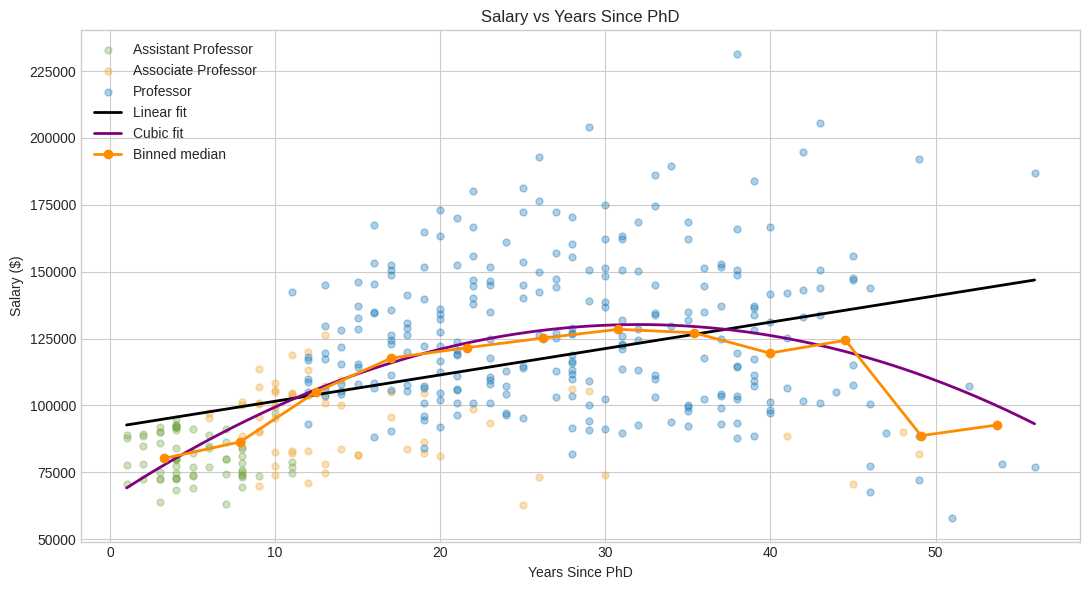

In [11]:
# Exercise 1 Solution
# Salary and years since PhD
# Compare raw observations, a linear fit, a cubic fit,
# and a binned-median profile.

x = df["years_since_phd"].to_numpy(dtype=float)
y = df["salary"].to_numpy(dtype=float)

# Sort observations by years since PhD.
sort_idx = np.argsort(x)
x_sorted = x[sort_idx]
y_sorted = y[sort_idx]

# Fit a straight line and a cubic polynomial.
linear_fit = np.poly1d(np.polyfit(x, y, deg=1))
cubic_fit = np.poly1d(np.polyfit(x, y, deg=3))

# Calculate binned medians using 13 equally spaced bin edges.
bin_edges = np.linspace(x.min(), x.max(), 13)

binned_df = df[["years_since_phd", "salary"]].copy()
binned_df["bin"] = pd.cut(
    binned_df["years_since_phd"],
    bins=bin_edges,
    include_lowest=True
)

binned_summary = (
    binned_df.groupby("bin", observed=False)["salary"]
    .agg(["count", "median"])
    .dropna(subset=["median"])
)

binned_summary["midpoint"] = [
    interval.mid for interval in binned_summary.index
]

# Display the supporting numerical table.
print("Binned median salary summary:")
display(binned_summary[["count", "median", "midpoint"]].round(2))

# Plot the observations and all three fitted summaries.
x_grid = np.linspace(x.min(), x.max(), 300)

fig, ax = plt.subplots(figsize=(11, 6))

# Raw scatterplot: one point per faculty record.
for rank in rank_order:
    subset = df[df["rank"] == rank]
    ax.scatter(
        subset["years_since_phd"],
        subset["salary"],
        color=colors[rank],
        alpha=0.35,
        s=25,
        label=rank_labels[rank]
    )

# Fitted summary 1: linear regression.
ax.plot(
    x_grid,
    linear_fit(x_grid),
    color="black",
    linewidth=2,
    label="Linear fit"
)

# Fitted summary 2: cubic polynomial.
ax.plot(
    x_grid,
    cubic_fit(x_grid),
    color="purple",
    linewidth=2,
    label="Cubic fit"
)

# Fitted summary 3: median salary within each bin.
ax.plot(
    binned_summary["midpoint"],
    binned_summary["median"],
    color="darkorange",
    marker="o",
    linewidth=2,
    label="Binned median"
)

ax.set_title("Salary vs Years Since PhD")
ax.set_xlabel("Years Since PhD")
ax.set_ylabel("Salary ($)")
ax.legend()
plt.tight_layout()
plt.show()

Answer to the question and Intrepretation:
1. Raw scatterplot: Each point represents one faculty member's years since PhD and salary. Color identifies academic rank.
2. Linear fit: The straight line summarizes the overall linear association between years since PhD and salary.
3. Cubic fit: The curved line allows a more flexible relationship than a straight line. It may reveal curvature, but it can also follow random variation.
4. Binned-median profile: Each marker represents the median salary among faculty members in a particular years-since-PhD interval.
5. Limitation: The dataset is observational. The lines show associations, not proof that additional years since PhD cause higher salaries. Academic rank and other factors may also influence salary.

### **Exercise 2: Rank and discipline**

Compare the exact crosstab, table plot, and mosaic plot. Explain which display best supports exact lookup, quick count comparison, and composition analysis.


Exact counts by academic rank and discipline:


discipline,A,B
rank,,
AsstProf,24,43
AssocProf,26,38
Prof,131,135


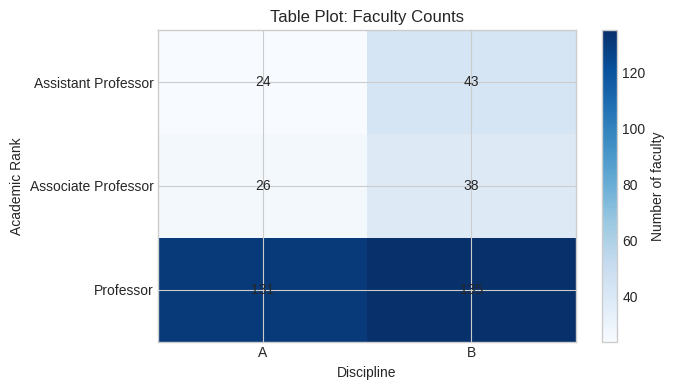

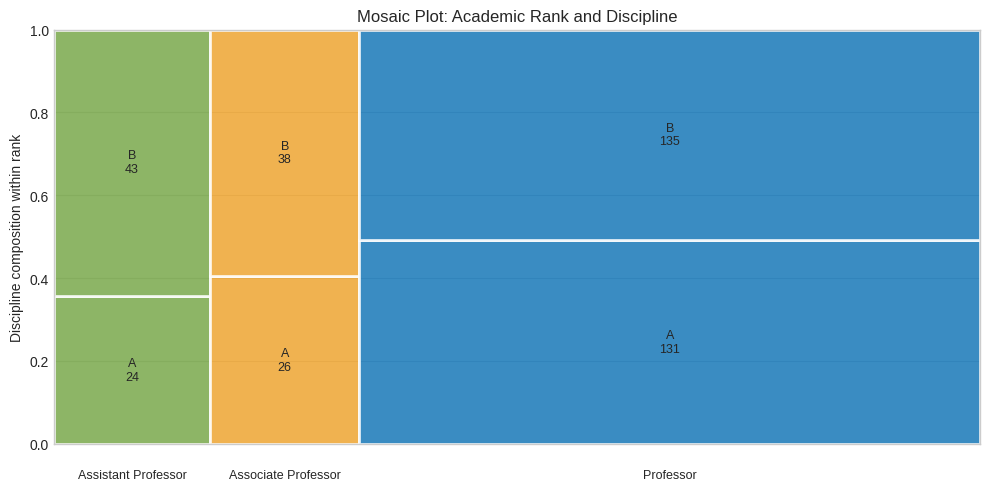

In [12]:
# Exercise 2 Solution
# Rank and discipline
# Compare an exact crosstab, a table plot, and a mosaic plot.

# 1. Exact contingency table.
counts = pd.crosstab(
    df["rank"],
    df["discipline"]
).reindex(
    index=rank_order,
    columns=["A", "B"],
    fill_value=0
)

print("Exact counts by academic rank and discipline:")
display(counts)

# 2. Table plot: use a colored grid with exact counts.
fig, ax = plt.subplots(figsize=(7, 4))

matrix = counts.to_numpy()

im = ax.imshow(matrix, aspect="auto", cmap="Blues")

ax.set_xticks(range(len(counts.columns)))
ax.set_xticklabels(counts.columns)

ax.set_yticks(range(len(counts.index)))
ax.set_yticklabels([rank_labels[str(rank)] for rank in counts.index])

ax.set_xlabel("Discipline")
ax.set_ylabel("Academic Rank")
ax.set_title("Table Plot: Faculty Counts")

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(
            j,
            i,
            str(matrix[i, j]),
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="Number of faculty")
plt.tight_layout()
plt.show()


# 3. Mosaic plot.
# Width = share of all records in each rank.
# Height = discipline share within that rank.
# Area = share of the full dataset in the rank-discipline cell.

from matplotlib.patches import Rectangle

total_count = counts.to_numpy().sum()

fig, ax = plt.subplots(figsize=(10, 5))

x_start = 0.0

for rank in rank_order:
    rank_total = counts.loc[rank].sum()

    if rank_total == 0:
        continue

    width = rank_total / total_count
    y_start = 0.0

    for discipline in ["A", "B"]:
        cell_count = counts.loc[rank, discipline]
        height = cell_count / rank_total

        rect = Rectangle(
            (x_start, y_start),
            width,
            height,
            facecolor=colors[rank],
            edgecolor="white",
            linewidth=2,
            alpha=0.85
        )

        ax.add_patch(rect)

        if cell_count > 0:
            ax.text(
                x_start + width / 2,
                y_start + height / 2,
                f"{discipline}\n{cell_count}",
                ha="center",
                va="center",
                fontsize=9
            )

        y_start += height

    ax.text(
        x_start + width / 2,
        -0.06,
        rank_labels[rank],
        ha="center",
        va="top",
        fontsize=9
    )

    x_start += width

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks([])
ax.set_ylabel("Discipline composition within rank")
ax.set_title("Mosaic Plot: Academic Rank and Discipline")

plt.tight_layout()
plt.show()

Answer to the questions and Intreprtation:

- Exact lookup: The contingency table is best because it displays the precise count for every rank-discipline combination.
- Quick count comparison: The table plot makes larger and smaller counts easy to identify visually, while the printed numbers preserve exact values.
- Composition analysis: The mosaic plot is useful because it displays both the relative size of each rank and the composition of disciplines within that rank.
- Limitation: The mosaic plot requires more interpretation than the crosstab. For an exact numerical answer, consult the table rather than estimating a rectangle's area.

### **Exercise 3: Mean salary profiles**

Compare the ordered line plot with the area-between-profiles chart. Report exact differences from the supporting table and discuss unequal group sizes.


Mean salary by rank and sex:


sex,Female,Male
rank,,
AsstProf,78049.91,81311.46
AssocProf,88512.80,94869.70
Prof,121967.61,127120.82


Sample size by rank and sex:


sex,Female,Male
rank,,
AsstProf,11,56
AssocProf,10,54
Prof,18,248


Mean salary differences and sample sizes:


,Male mean,Female mean,Male count,Female count,Male minus Female,Absolute difference
AsstProf,81311.46,78049.91,56,11,3261.56,3261.56
AssocProf,94869.70,88512.80,54,10,6356.90,6356.90
Prof,127120.82,121967.61,248,18,5153.21,5153.21


Largest absolute difference: AssocProf (6,356.90)


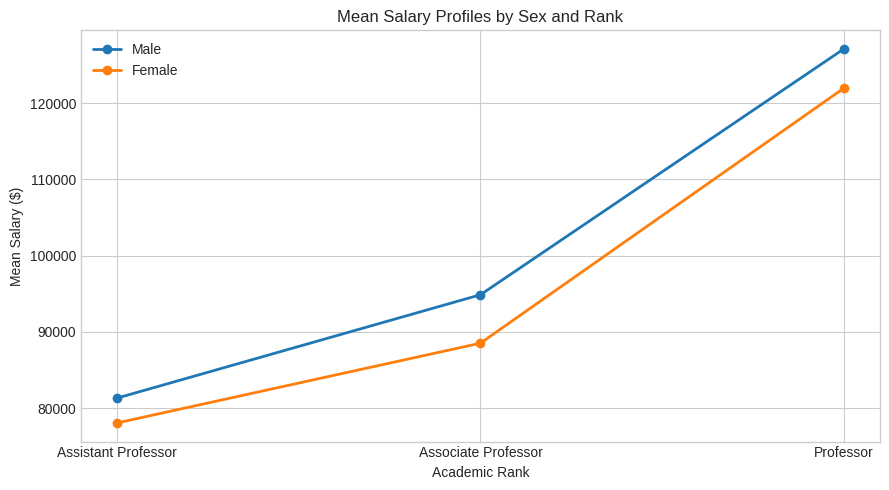

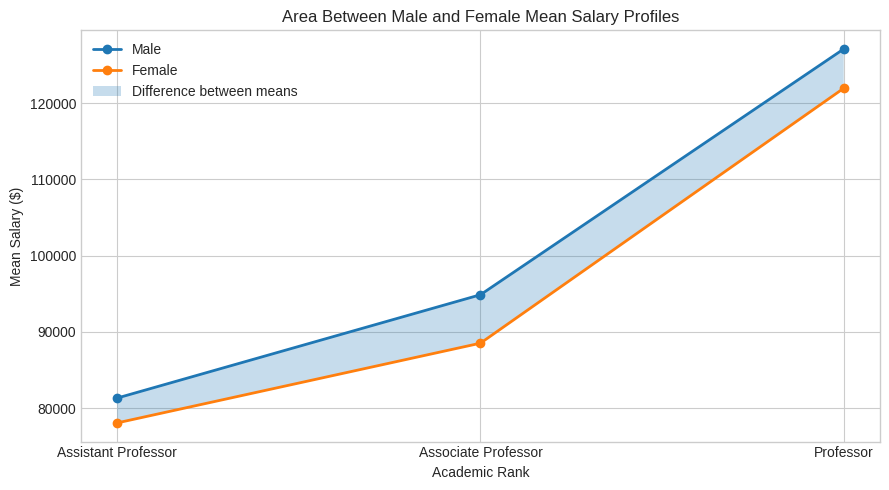

In [13]:
# Exercise 3 Solution
# Mean salary profiles by sex and academic rank

# Calculate the mean salary and sample size for each group.
profile_data = (
    df.groupby(["rank", "sex"], observed=True)["salary"]
    .agg(["mean", "count"])
    .reset_index()
)

mean_profiles = profile_data.pivot(
    index="rank",
    columns="sex",
    values="mean"
).reindex(rank_order)

count_profiles = profile_data.pivot(
    index="rank",
    columns="sex",
    values="count"
).reindex(rank_order)

print("Mean salary by rank and sex:")
display(mean_profiles.round(2))

print("Sample size by rank and sex:")
display(count_profiles)

# Identify the Male and Female columns.
sex_lookup = {
    str(value).strip().lower(): value
    for value in mean_profiles.columns
}

male_column = next(
    (value for key, value in sex_lookup.items()
     if key in ["male", "m"]),
    None
)

female_column = next(
    (value for key, value in sex_lookup.items()
     if key in ["female", "f"]),
    None
)

if male_column is None or female_column is None:
    raise ValueError(
        "Male and Female categories were not identified. "
        "Check the sex labels in mean_profiles.columns."
    )

# Create the supporting table of salary differences.
profile_check = pd.DataFrame(index=rank_order)

profile_check["Male mean"] = mean_profiles[male_column]
profile_check["Female mean"] = mean_profiles[female_column]

profile_check["Male count"] = count_profiles[male_column]
profile_check["Female count"] = count_profiles[female_column]

profile_check["Male minus Female"] = (
    profile_check["Male mean"] - profile_check["Female mean"]
)

profile_check["Absolute difference"] = (
    profile_check["Male minus Female"].abs()
)

print("Mean salary differences and sample sizes:")
display(profile_check.round(2))

# Report the largest absolute difference.
largest_difference_rank = (
    profile_check["Absolute difference"].idxmax()
)

print(
    f"Largest absolute difference: {largest_difference_rank} "
    f"({profile_check.loc[largest_difference_rank, 'Absolute difference']:,.2f})"
)


# Chart 1: Ordered line plot.
x_positions = np.arange(len(rank_order))

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    x_positions,
    mean_profiles[male_column],
    marker="o",
    linewidth=2,
    label="Male"
)

ax.plot(
    x_positions,
    mean_profiles[female_column],
    marker="o",
    linewidth=2,
    label="Female"
)

ax.set_xticks(x_positions)
ax.set_xticklabels([rank_labels[rank] for rank in rank_order])
ax.set_xlabel("Academic Rank")
ax.set_ylabel("Mean Salary ($)")
ax.set_title("Mean Salary Profiles by Sex and Rank")
ax.legend()

plt.tight_layout()
plt.show()


# Chart 2: Area between the mean profiles.
male_means = mean_profiles[male_column].to_numpy(dtype=float)
female_means = mean_profiles[female_column].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    x_positions,
    male_means,
    marker="o",
    linewidth=2,
    label="Male"
)

ax.plot(
    x_positions,
    female_means,
    marker="o",
    linewidth=2,
    label="Female"
)

ax.fill_between(
    x_positions,
    male_means,
    female_means,
    alpha=0.25,
    label="Difference between means"
)

ax.set_xticks(x_positions)
ax.set_xticklabels([rank_labels[rank] for rank in rank_order])
ax.set_xlabel("Academic Rank")
ax.set_ylabel("Mean Salary ($)")
ax.set_title("Area Between Male and Female Mean Salary Profiles")
ax.legend()

plt.tight_layout()
plt.show()

Answer to the questionsa and Interpretation:

- Ordered line plot: This makes it easier to compare mean salaries across the three ranks and examine how the difference between the two sex categories changes across ranks.
- Area-between-profiles chart: The shaded area emphasizes the gap between the two mean-salary profiles. The vertical distance between the lines at each rank represents the difference in mean salary.
- Unequal group sizes: The number of observations can differ between Male and Female faculty at each rank. Smaller groups may produce less stable estimates, so the counts should be considered alongside the means.
- Limitation: Academic ranks are ordered categories, not points in time. The lines are visual comparisons between group means, not evidence of salary growth over time or proof that sex causes the observed salary differences.